# Resúmenes de los artículos de la revisión de literatura

Un resumen por cada artículo analizado: qué hicieron los autores, cómo configuraron el estudio y para qué usaron cada método. **No** se explica cómo funciona cada método; cuando un método ya está explicado en el [notebook de métodos](../metodos/metodos.ipynb), se enlaza a su sección.

Estructura de cada artículo: Referencia → Problema → Pregunta → Cómo lo resolvieron (configuración y procedimiento paso a paso, con figuras) → Métodos y propósito → Validación y resultados → Limitaciones → Conclusiones.

Las figuras son **esquemas propios** generados con matplotlib para ilustrar lo que hicieron los autores; no son copias ni redibujos de las figuras de los artículos. También se guardan como PNG en `figuras/`.

<a id="indice"></a>
## Índice

1. [Malekjafarian y OBrien (2017) — Uso de un vehículo que pasa para estimar las formas modales de un puente](#malekjafarian-2017)
2. [Mei et al. (2021) — Formas modales con vehículos a velocidad de tráfico mediante completado de matrices dispersas](#mei-2021)

## Tabla de contenido

| Autores | Año | Título corto |
|---|---|---|
| [Malekjafarian y OBrien](#malekjafarian-obrien-2017) | 2017 | Uso de un vehículo que pasa para estimar las formas modales de un puente |
| [Mei et al.](#mei-2021) | 2021 | Formas modales con vehículos a velocidad de tráfico mediante completado de matrices dispersas |

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

COLOR_SIGNAL = "#8a8984"   # neutral gray
COLOR_1 = "#2a78d6"        # blue
COLOR_2 = "#eb6834"        # orange
COLOR_TRUE = "#0b0b0b"     # exact reference / ink

FIG_DIR = Path("figuras")  # PNG copies of every figure
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#8a8984",
    "legend.frameon": False,
})

<a id="malekjafarian-obrien-2017"></a><a id="malekjafarian-2017"></a>
# Malekjafarian y OBrien (2017)

## 1. Referencia

Malekjafarian, A. y OBrien, E. J. (2017). *On the use of a passing vehicle for the estimation of bridge mode shapes*. Journal of Sound and Vibration, 397, 77–91. https://doi.org/10.1016/j.jsv.2017.02.051. University College Dublin.

## 2. Problema

Medir las formas modales de un puente con sensores fijos es caro, porque hay que instrumentar cada puente. Con un vehículo que pasa es más barato, pero la respuesta del puente queda tapada por la del vehículo y la rugosidad, y la amplitud medida no es directamente la forma modal, porque el tamaño de la vibración cambia mientras el vehículo cruza.

## 3. Pregunta

¿Se pueden estimar las formas modales de un puente a partir de las aceleraciones medidas en un vehículo que pasa, excitando el puente desde el propio vehículo?

## 4. Cómo lo resolvieron

### Configuración del estudio

Todo es simulación numérica en MATLAB, con interacción vehículo-puente:

- **Puente:** viga simplemente apoyada de 15 m, con frecuencias naturales de 5.65, 22.62 y 50.89 Hz.
- **Vehículo:** convoy formado por un camión de 3 ejes y dos remolques, cruzando a 2 m/s.
- **Excitador:** va en el eje 4, que es el primer eje del primer remolque. Aplica una fuerza senoidal (3 kN con carretera lisa y 30 kN con rugosidad clase A) a una frecuencia cercana a la del modo que se quiere obtener.
- **Sensores:** acelerómetros en los ejes 6 y 7, en el segundo remolque, separados 1 m. Solo miden; no excitan.
- **Dos pasadas:** una con el excitador a 5.5 Hz, para el primer modo, y otra a 22.9 Hz, para el segundo.

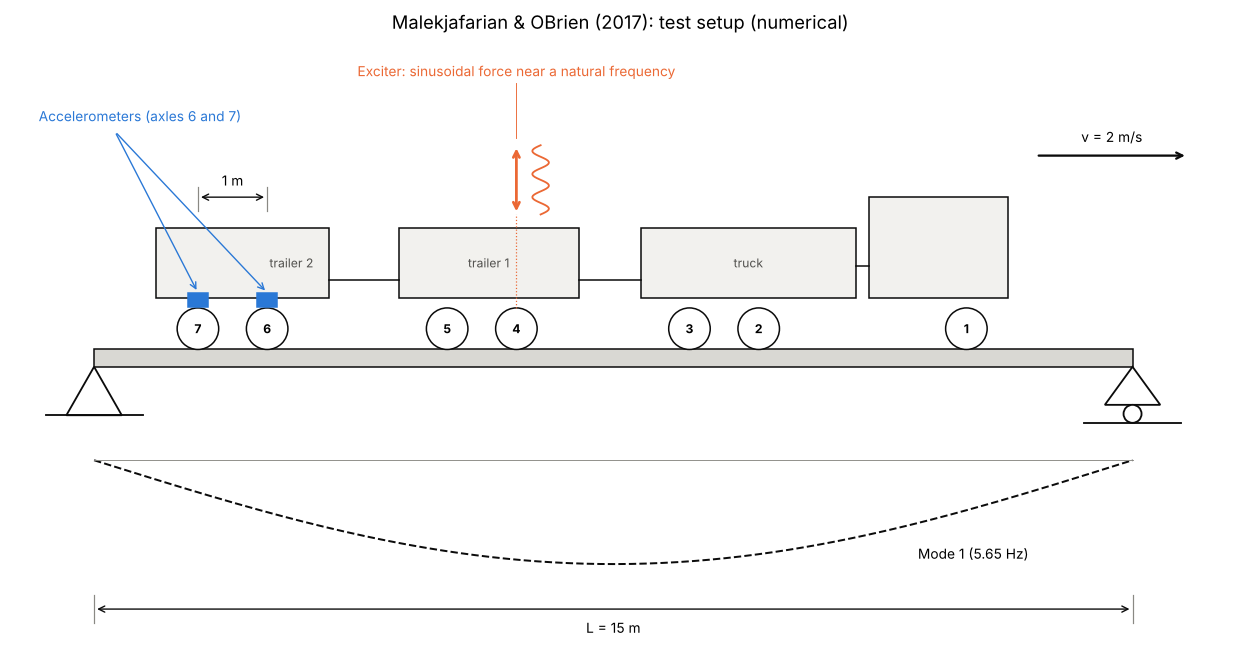

In [2]:
# Figure 1: test setup (schematic, not to scale except the 1 m axle spacing 6-7)
L = 15.0
fig, ax = plt.subplots(figsize=(12, 6.2))

# --- Bridge deck and supports ---
ax.add_patch(patches.Rectangle((0, -0.25), L, 0.25, facecolor="#d9d8d3", edgecolor=COLOR_TRUE, lw=1))
ax.add_patch(patches.Polygon([(0, -0.25), (-0.4, -0.95), (0.4, -0.95)], closed=True,
                             facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))            # pin
ax.add_patch(patches.Polygon([(L, -0.25), (L - 0.4, -0.8), (L + 0.4, -0.8)], closed=True,
                             facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))            # roller
ax.add_patch(patches.Circle((L, -0.93), 0.13, facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))
ax.plot([-0.7, 0.7], [-0.95, -0.95], color=COLOR_TRUE, lw=1.2)
ax.plot([L - 0.7, L + 0.7], [-1.06, -1.06], color=COLOR_TRUE, lw=1.2)

# --- Vehicle: axle positions (m); driving direction to the right ---
axles = {7: 1.5, 6: 2.5, 5: 5.1, 4: 6.1, 3: 8.6, 2: 9.6, 1: 12.6}
wheel_r = 0.3
bodies = [(0.9, 3.4, 1.0), (4.4, 7.0, 1.0), (7.9, 11.0, 1.0)]   # (x0, x1, height)
for x0, x1, h in bodies:
    ax.add_patch(patches.Rectangle((x0, 0.75), x1 - x0, h, facecolor="#f2f1ee",
                                   edgecolor=COLOR_TRUE, lw=1))
ax.add_patch(patches.Rectangle((11.2, 0.75), 2.0, 1.45, facecolor="#f2f1ee",
                               edgecolor=COLOR_TRUE, lw=1))                           # truck cab
ax.plot([11.0, 11.2], [1.2, 1.2], color=COLOR_TRUE, lw=1)
ax.plot([3.4, 4.4], [1.0, 1.0], color=COLOR_TRUE, lw=1)                                  # couplings
ax.plot([7.0, 7.9], [1.0, 1.0], color=COLOR_TRUE, lw=1)
for name, (x0, x1, _) in zip(["trailer 2", "trailer 1", "truck"], bodies):
    label_x = x1 - 0.55 if name == "trailer 2" else (x0 + x1) / 2   # keep clear of sensor arrows
    ax.text(label_x, 1.25, name, ha="center", va="center", fontsize=8, color="#52514e")

for n, x in axles.items():
    ax.add_patch(patches.Circle((x, wheel_r), wheel_r, facecolor="white", edgecolor=COLOR_TRUE, lw=1))
    ax.text(x, wheel_r, str(n), ha="center", va="center", fontsize=8, fontweight="bold")

# --- 1 m spacing between axles 6 and 7 ---
for n in (6, 7):
    ax.plot([axles[n]] * 2, [2.0, 2.35], color=COLOR_SIGNAL, lw=0.8)
ax.annotate("", xy=(axles[7], 2.2), xytext=(axles[6], 2.2),
            arrowprops=dict(arrowstyle="<->", color=COLOR_TRUE, lw=0.9))
ax.text((axles[6] + axles[7]) / 2, 2.32, "1 m", ha="center", va="bottom", fontsize=9)

# --- Accelerometers on axles 6 and 7 ---
for n in (6, 7):
    ax.add_patch(patches.Rectangle((axles[n] - 0.14, 0.62), 0.28, 0.2, facecolor=COLOR_1,
                                   edgecolor=COLOR_1))
ax.text(-0.8, 3.25, "Accelerometers (axles 6 and 7)", fontsize=9, color=COLOR_1, ha="left",
        va="bottom")
for n in (7, 6):
    ax.annotate("", xy=(axles[n], 0.82), xytext=(0.3, 3.15),
                arrowprops=dict(arrowstyle="->", color=COLOR_1, lw=0.9))

# --- Exciter on axle 4: double vertical arrow + small sine trace ---
x4 = axles[4]
ax.annotate("", xy=(x4, 2.95), xytext=(x4, 1.95),
            arrowprops=dict(arrowstyle="<->", color=COLOR_2, lw=1.8))
sine_y = np.linspace(1.95, 2.95, 60)
ax.plot(x4 + 0.35 + 0.12 * np.sin(2 * np.pi * 3 * (sine_y - 1.95)), sine_y, color=COLOR_2, lw=1.2)
ax.plot([x4, x4], [0.6, 1.95], color=COLOR_2, lw=0.8, ls=":")
ax.text(x4, 3.9, "Exciter: sinusoidal force near a natural frequency", ha="center",
        va="bottom", fontsize=9, color=COLOR_2)
ax.plot([x4, x4], [3.05, 3.85], color=COLOR_2, lw=0.6)

# --- Direction of travel ---
ax.annotate("", xy=(15.8, 2.8), xytext=(13.6, 2.8),
            arrowprops=dict(arrowstyle="->", color=COLOR_TRUE, lw=1.5))
ax.text(14.7, 2.95, "v = 2 m/s", ha="center", va="bottom", fontsize=9)

# --- Mode 1 shape (exaggerated) below the deck ---
x_shape = np.linspace(0, L, 200)
base = -1.6
ax.plot(x_shape, base - 1.5 * np.sin(np.pi * x_shape / L), "--", color=COLOR_TRUE, lw=1.3)
ax.plot([0, L], [base, base], color=COLOR_SIGNAL, lw=0.6)
ax.text(11.9, -2.95, "Mode 1 (5.65 Hz)", fontsize=9, ha="left", va="center")

# --- Span dimension ---
ax.annotate("", xy=(0, -3.75), xytext=(L, -3.75),
            arrowprops=dict(arrowstyle="<->", color=COLOR_TRUE, lw=0.9))
for x in (0, L):
    ax.plot([x, x], [-3.55, -3.95], color=COLOR_SIGNAL, lw=0.8)
ax.text(L / 2, -3.9, "L = 15 m", ha="center", va="top", fontsize=9)

ax.set_xlim(-1.2, 16.4)
ax.set_ylim(-4.5, 4.5)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("Malekjafarian & OBrien (2017): test setup (numerical)")
fig.tight_layout()
fig.savefig(FIG_DIR / "malekjafarian_obrien_2017_fig1_setup.png", dpi=150, bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Malekjafarian y OBrien (2017).*

### Procedimiento paso a paso

1. **Excitación en resonancia:** el excitador, sintonizado cerca de una frecuencia natural, pone en resonancia ese modo, de modo que su vibración domina sobre los demás modos, la dinámica del vehículo y la rugosidad (Fig. 3 del artículo).
2. **Medición:** los ejes 6 y 7 registran la aceleración mientras cruzan el puente (Fig. 3a y 3c). La FFT confirma que domina la frecuencia del modo excitado (Fig. 3b y 3d).
3. **Eliminación de la rugosidad** (solo en el caso con perfil de carretera): se restan las señales entre ejes (eje 6 menos eje 4 y eje 7 menos eje 5) para quitar el efecto del perfil (Fig. 12).
4. **Aislamiento del modo con la [EMD](../metodos/metodos.ipynb#emd):** se separa la señal de cada eje en componentes (IMF) y se elige la que corresponde al modo excitado (Fig. 4a y 5a).
5. **[Transformada de Hilbert](../metodos/metodos.ipynb#transformada-de-hilbert):** se aplica a esa componente para obtener su frecuencia instantánea, que confirma que es el modo correcto (Fig. 4b y 5b), y su amplitud instantánea, la envolvente.
6. **Envolvente contra posición:** se grafica la amplitud de cada eje contra su posición en el puente, y se suaviza y recorta en los extremos (Fig. 6). Se parece a la forma modal, pero no lo es, porque el tamaño de la vibración cambia durante el cruce.
7. **Reescalado:** se toman puntos cada 1 m; en cada instante se divide la amplitud del eje 6 entre la del eje 7 y se encadenan esas relaciones punto por punto, para armar la forma modal completa sin depender del tamaño de la vibración (Fig. 7; ver la [sección de fundamentos](../metodos/metodos.ipynb#fundamentos)).
8. **Resultado:** forma modal reconstruida comparada con la exacta del modelo (Fig. 8 para el primer modo y Fig. 10 para el segundo).

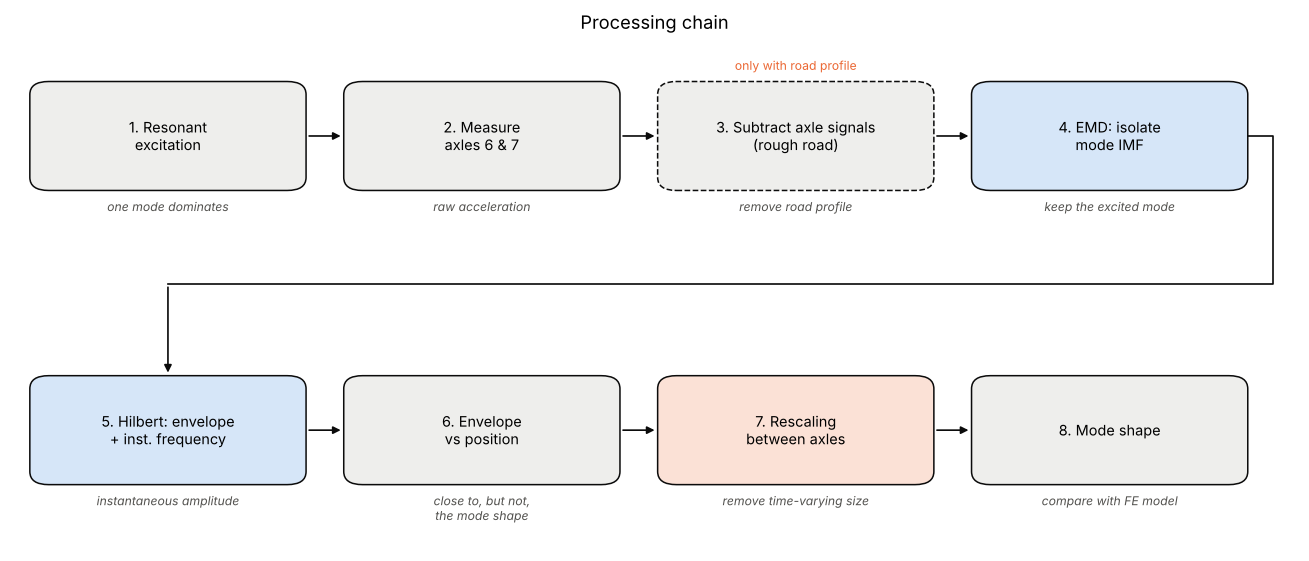

In [3]:
# Figure 2: processing chain (two rows of four boxes)
LIGHT_GRAY, LIGHT_BLUE, LIGHT_ORANGE = "#eeeeec", "#d6e6f8", "#fbe1d6"
steps = [
    ("1. Resonant\nexcitation", "one mode dominates", LIGHT_GRAY),
    ("2. Measure\naxles 6 & 7", "raw acceleration", LIGHT_GRAY),
    ("3. Subtract axle signals\n(rough road)", "remove road profile", LIGHT_GRAY),
    ("4. EMD: isolate\nmode IMF", "keep the excited mode", LIGHT_BLUE),
    ("5. Hilbert: envelope\n+ inst. frequency", "instantaneous amplitude", LIGHT_BLUE),
    ("6. Envelope\nvs position", "close to, but not,\nthe mode shape", LIGHT_GRAY),
    ("7. Rescaling\nbetween axles", "remove time-varying size", LIGHT_ORANGE),
    ("8. Mode shape", "compare with FE model", LIGHT_GRAY),
]
box_w, box_h = 0.84, 0.46
row_y = [2.1, 0.75]          # box centre y for row 1 and row 2
col_x = [0.5, 1.5, 2.5, 3.5]

fig, ax = plt.subplots(figsize=(12, 5.2))
centres = []
for i, (label, purpose, color) in enumerate(steps):
    cx, cy = col_x[i % 4], row_y[i // 4]
    centres.append((cx, cy))
    box = patches.FancyBboxPatch((cx - box_w / 2, cy - box_h / 2), box_w, box_h,
                                 boxstyle="round,pad=0.02,rounding_size=0.06",
                                 facecolor=color, edgecolor=COLOR_TRUE, lw=1,
                                 linestyle="--" if i == 2 else "-")
    ax.add_patch(box)
    ax.text(cx, cy, label, ha="center", va="center", fontsize=9.5)
    ax.text(cx, cy - box_h / 2 - 0.06, purpose, ha="center", va="top", fontsize=8,
            color="#52514e", style="italic")
ax.text(col_x[2], row_y[0] + box_h / 2 + 0.06, "only with road profile", ha="center",
        va="bottom", fontsize=8, color=COLOR_2)

arrow = dict(arrowstyle="-|>", color=COLOR_TRUE, lw=1.1)
for i in range(7):
    if i == 3:
        continue
    (x0, y0), (x1, y1) = centres[i], centres[i + 1]
    ax.annotate("", xy=(x1 - box_w / 2 - 0.02, y1), xytext=(x0 + box_w / 2 + 0.02, y0),
                arrowprops=arrow)
# Row 1 -> row 2: out of the right side of box 4, down, left, and into the top of box 5
x_right, y_mid = col_x[3] + box_w / 2 + 0.1, 1.42
ax.plot([col_x[3] + box_w / 2 + 0.02, x_right, x_right, col_x[0], col_x[0]],
        [row_y[0], row_y[0], y_mid, y_mid, y_mid], color=COLOR_TRUE, lw=1.1)
ax.annotate("", xy=(col_x[0], row_y[1] + box_h / 2 + 0.02), xytext=(col_x[0], y_mid),
            arrowprops=arrow)

ax.set_xlim(0, 4.1)
ax.set_ylim(0.2, 2.55)
ax.axis("off")
ax.set_title("Processing chain")
fig.tight_layout()
fig.savefig(FIG_DIR / "malekjafarian_obrien_2017_fig2_processing_chain.png", dpi=150,
            bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Malekjafarian y OBrien (2017).*

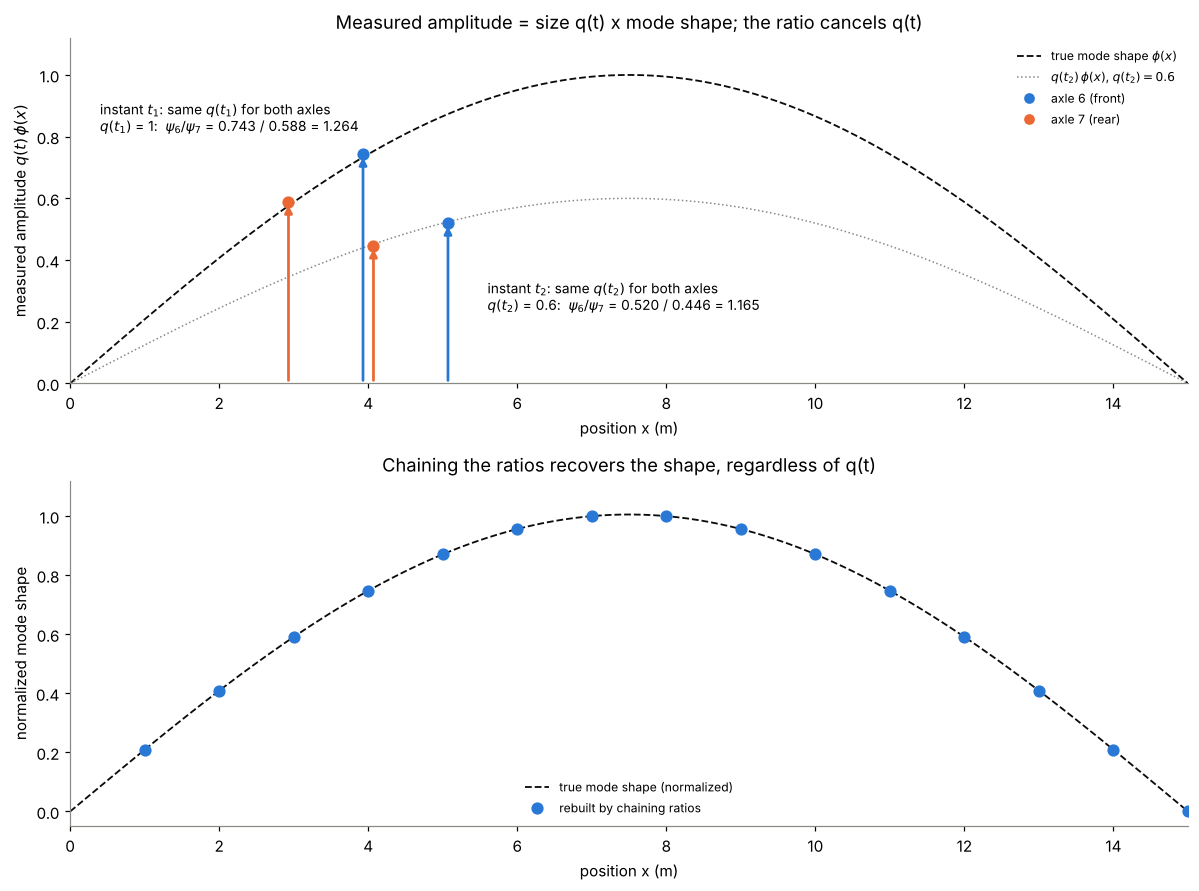

Max error between rebuilt and true shape: 2.2e-16


In [4]:
# Figure 3: rescaling between axles 6 (front) and 7 (rear)
L = 15.0
phi = lambda x: np.sin(np.pi * x / L)        # first mode shape
x_fine = np.linspace(0, L, 300)

fig, axes = plt.subplots(2, 1, figsize=(11, 8.2))

# --- Top: two instants, same q for both axles at each instant ---
ax = axes[0]
ax.plot(x_fine, phi(x_fine), "--", color=COLOR_TRUE, lw=1.2, label=r"true mode shape $\phi(x)$")
ax.plot(x_fine, 0.6 * phi(x_fine), ":", color=COLOR_SIGNAL, lw=1, label=r"$q(t_2)\,\phi(x)$, $q(t_2) = 0.6$")
instants = [("t_1", 1.0, 3.0, -0.07), ("t_2", 0.6, 4.0, 0.07)]   # name, q, rear axle x, x offset
for name, q, x_rear, dx in instants:
    x_front = x_rear + 1.0
    psi_7, psi_6 = q * phi(x_rear), q * phi(x_front)
    for x, psi, color in [(x_rear, psi_7, COLOR_2), (x_front, psi_6, COLOR_1)]:
        ax.annotate("", xy=(x + dx, psi), xytext=(x + dx, 0),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.8))
        ax.plot(x + dx, psi, "o", ms=7, color=color, zorder=3)
    text_x = 0.4 if name == "t_1" else 5.6
    text_y = 0.86 if name == "t_1" else 0.28
    ax.text(text_x, text_y,
            f"instant ${name}$: same $q({name})$ for both axles\n"
            f"$q({name})$ = {q:g}:  $\\psi_6/\\psi_7$ = {psi_6:.3f} / {psi_7:.3f} = {psi_6 / psi_7:.3f}",
            fontsize=9, va="center", ha="left")
ax.plot([], [], "o", color=COLOR_1, label="axle 6 (front)")
ax.plot([], [], "o", color=COLOR_2, label="axle 7 (rear)")
ax.set_xlim(0, L)
ax.set_ylim(0, 1.12)
ax.set_xlabel("position x (m)")
ax.set_ylabel(r"measured amplitude $q(t)\,\phi(x)$")
ax.set_title("Measured amplitude = size q(t) x mode shape; the ratio cancels q(t)")
ax.legend(loc="upper right", fontsize=8)

# --- Bottom: chain the ratios with a different random q at every step ---
rng = np.random.default_rng(0)
x_points = np.arange(1.0, L + 1.0, 1.0)              # 1, 2, ..., 15 m
phi_rebuilt = [1.0]                                   # start at phi(1) (arbitrary scale)
for x_rear in x_points[:-1]:
    q = rng.uniform(0.2, 1.5)                         # unknown, changes every step
    psi_7, psi_6 = q * phi(x_rear), q * phi(x_rear + 1.0)
    phi_rebuilt.append(phi_rebuilt[-1] * psi_6 / psi_7)
phi_rebuilt = np.array(phi_rebuilt)
phi_rebuilt_norm = phi_rebuilt / phi_rebuilt.max()
phi_true_norm = phi(x_points) / phi(x_points).max()

ax = axes[1]
ax.plot(x_fine, phi(x_fine) / phi(x_points).max(), "--", color=COLOR_TRUE, lw=1.2,
        label="true mode shape (normalized)")
ax.plot(x_points, phi_rebuilt_norm, "o", ms=7, color=COLOR_1, label="rebuilt by chaining ratios")
ax.set_xlim(0, L)
ax.set_ylim(-0.05, 1.12)
ax.set_xlabel("position x (m)")
ax.set_ylabel("normalized mode shape")
ax.set_title("Chaining the ratios recovers the shape, regardless of q(t)")
ax.legend(loc="lower center", fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "malekjafarian_obrien_2017_fig3_rescaling.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Max error between rebuilt and true shape: {np.max(np.abs(phi_rebuilt_norm - phi_true_norm)):.1e}")

*Esquema propio basado en la descripción de Malekjafarian y OBrien (2017).*

En cada instante los dos ejes ven el mismo tamaño de vibración $q(t)$, así que al dividir sus amplitudes ese tamaño se cancela y queda solo la proporción de la forma modal entre dos puntos separados 1 m. Encadenando esas proporciones se reconstruye la forma completa.

## 5. Métodos y propósito

| Método | Para qué se usó |
|---|---|
| Excitador sintonizado en el vehículo | Hacer dominar un solo modo del puente mediante resonancia |
| Dos ejes medidos a 1 m de distancia | Tener mediciones simultáneas para el reescalado |
| Resta de señales entre ejes | Eliminar el efecto de la rugosidad |
| FFT | Comprobar qué frecuencia domina en la señal |
| [EMD](../metodos/metodos.ipynb#emd) | Aislar la componente del modo excitado |
| [Transformada de Hilbert](../metodos/metodos.ipynb#transformada-de-hilbert) | Obtener la envolvente (amplitud instantánea) y confirmar la frecuencia |
| Reescalado | Convertir las envolventes en la forma modal completa |

## 6. Validación y resultados

- Solo numérica; no hay ensayo en un puente real.
- Obtuvieron los dos primeros modos con lo que los autores llaman "precisión aceptable", con carretera lisa y con rugosidad clase A. No dan MAC ni error numérico; la comparación es visual.
- Rango útil de frecuencia del excitador: de 5.4 a 5.8 Hz para el primer modo y de 22.0 a 23.2 Hz para el segundo.
- Con rugosidad clase C la precisión es pobre.

## 7. Limitaciones

- La velocidad de 2 m/s no es realista y obligaría casi a cerrar el puente.
- La fuerza necesaria, de hasta 30 kN, implica equipo pesado.
- El método es sensible al ruido, a variaciones de velocidad y a modos con frecuencias cercanas.

## 8. Conclusiones

- La excitación externa permite acceder a la energía de la respuesta del puente en las frecuencias clave.
- La amplitud medida no es la forma modal, solo está relacionada con ella en el instante de la medición; esto corrige lo que suponían estudios anteriores.
- Con el reescalado entre dos ejes consecutivos se construye la forma modal completa.
- El método puede usarse con rugosidad si se restan las señales entre ejes.

[↑ Volver al índice](#indice)

---

<a id="mei-2021"></a>
# Mei et al. (2021)

## 1. Referencia

Mei, Q., Shirzad-Ghaleroudkhani, N., Gül, M., Ghahari, S. F. y Taciroglu, E. (2021). *Bridge mode shape identification using moving vehicles at traffic speeds through non-parametric sparse matrix completion*. Structural Control and Health Monitoring, 28(7), e2747. https://doi.org/10.1002/stc.2747.

- **Afiliaciones:** autores 1–3, University of Alberta (Gül, autor de correspondencia); autores 4–5, UCLA.
- **Fechas:** recibido el 2 de junio de 2020; aceptado el 5 de marzo de 2021.

## 2. Problema

- Las formas modales sirven para evaluar el estado de un puente, pero instrumentar con sensores fijos miles de puentes es caro.
- Los métodos anteriores con vehículos ([Malekjafarian y OBrien, 2017](#malekjafarian-obrien-2017); Yang et al., 2014) usan la frecuencia o la transformada de Hilbert. Exigen velocidades bajas, porque el tiempo de interacción vehículo-puente es corto, y requieren criterio de ingeniería para decidir el signo de la forma modal.
- Oshima et al. (2014) llevaban las mediciones a puntos fijos con interpolación de Lagrange de orden alto, que es inestable al invertirse.

## 3. Pregunta de investigación

¿Se pueden identificar las formas modales con pocos sensores en vehículos que circulan a velocidad de tráfico, sin usar información en el dominio de la frecuencia ni un modelo del puente?

## 4. Cómo lo resolvieron (flujo general)

Aceleración en los ejes → integración doble → desplazamiento → [mapeo a puntos fijos virtuales](../metodos/metodos.ipynb#mapeo-vfp) → matriz con huecos → [soft imputing](../metodos/metodos.ipynb#soft-imputing) → matriz completa → [SVD](../metodos/metodos.ipynb#svd-formas-modales) → formas modales → comparación con MAC.

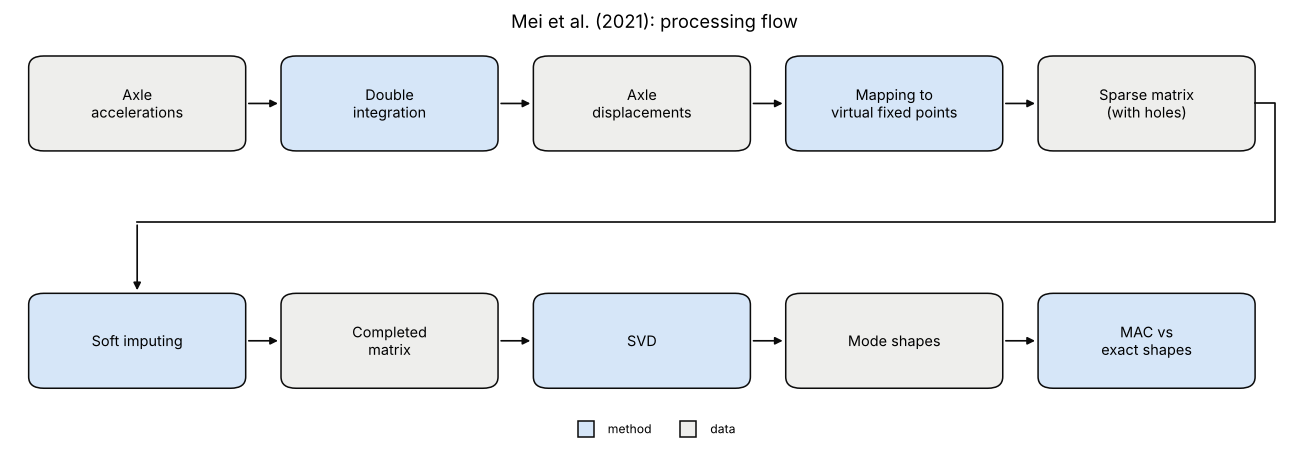

In [5]:
# Figure 1: Mei et al. (2021) processing flow (two rows of five boxes)
LIGHT_GRAY, LIGHT_BLUE = "#eeeeec", "#d6e6f8"
flow_steps = [
    ("Axle\naccelerations", LIGHT_GRAY),
    ("Double\nintegration", LIGHT_BLUE),
    ("Axle\ndisplacements", LIGHT_GRAY),
    ("Mapping to\nvirtual fixed points", LIGHT_BLUE),
    ("Sparse matrix\n(with holes)", LIGHT_GRAY),
    ("Soft imputing", LIGHT_BLUE),
    ("Completed\nmatrix", LIGHT_GRAY),
    ("SVD", LIGHT_BLUE),
    ("Mode shapes", LIGHT_GRAY),
    ("MAC vs\nexact shapes", LIGHT_BLUE),
]
box_w, box_h = 0.82, 0.46
row_y = [1.85, 0.6]
col_x = [0.5, 1.5, 2.5, 3.5, 4.5]

fig, ax = plt.subplots(figsize=(12, 4.2))
centres = []
for i, (label, color) in enumerate(flow_steps):
    cx, cy = col_x[i % 5], row_y[i // 5]
    centres.append((cx, cy))
    ax.add_patch(patches.FancyBboxPatch((cx - box_w / 2, cy - box_h / 2), box_w, box_h,
                                        boxstyle="round,pad=0.02,rounding_size=0.06",
                                        facecolor=color, edgecolor=COLOR_TRUE, lw=1))
    ax.text(cx, cy, label, ha="center", va="center", fontsize=9.5)

arrow = dict(arrowstyle="-|>", color=COLOR_TRUE, lw=1.1)
for i in range(9):
    if i == 4:
        continue
    (x0, y0), (x1, y1) = centres[i], centres[i + 1]
    ax.annotate("", xy=(x1 - box_w / 2 - 0.02, y1), xytext=(x0 + box_w / 2 + 0.02, y0),
                arrowprops=arrow)
x_right, y_mid = col_x[4] + box_w / 2 + 0.1, (row_y[0] + row_y[1]) / 2
ax.plot([col_x[4] + box_w / 2 + 0.02, x_right, x_right, col_x[0], col_x[0]],
        [row_y[0], row_y[0], y_mid, y_mid, y_mid], color=COLOR_TRUE, lw=1.1)
ax.annotate("", xy=(col_x[0], row_y[1] + box_h / 2 + 0.02), xytext=(col_x[0], y_mid),
            arrowprops=arrow)
ax.plot([], [], "s", ms=10, color=LIGHT_BLUE, mec=COLOR_TRUE, label="method")
ax.plot([], [], "s", ms=10, color=LIGHT_GRAY, mec=COLOR_TRUE, label="data")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8)

ax.set_xlim(0, 5.1)
ax.set_ylim(0.2, 2.2)
ax.axis("off")
ax.set_title("Mei et al. (2021): processing flow")
fig.tight_layout()
fig.savefig(FIG_DIR / "mei2021_flujo.png", dpi=150, bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Mei et al. (2021).*

## 5. Configuración del estudio (numérico)

- **Modelo en ABAQUS:** viga simplemente apoyada de 40 m, sección de 3 × 1.5 m, concreto con $\rho$ = 2400 kg/m³ y $E$ = 27.5 GPa. Frecuencias naturales de 1.44, 5.76 y 12.95 Hz.
- **"Carro":** dos puntos de contacto móviles (MMP) separados 2.5 m, a 40 km/h. Análisis dinámico implícito lineal con contacto y muestreo a 200 Hz. La simulación termina cuando el punto delantero llega al final del puente.
- **Puntos fijos virtuales:** 10 VFP equiespaciados, con los de los extremos sobre los apoyos. Resulta una matriz de 10 × 677 con **66.41 %** de datos faltantes.

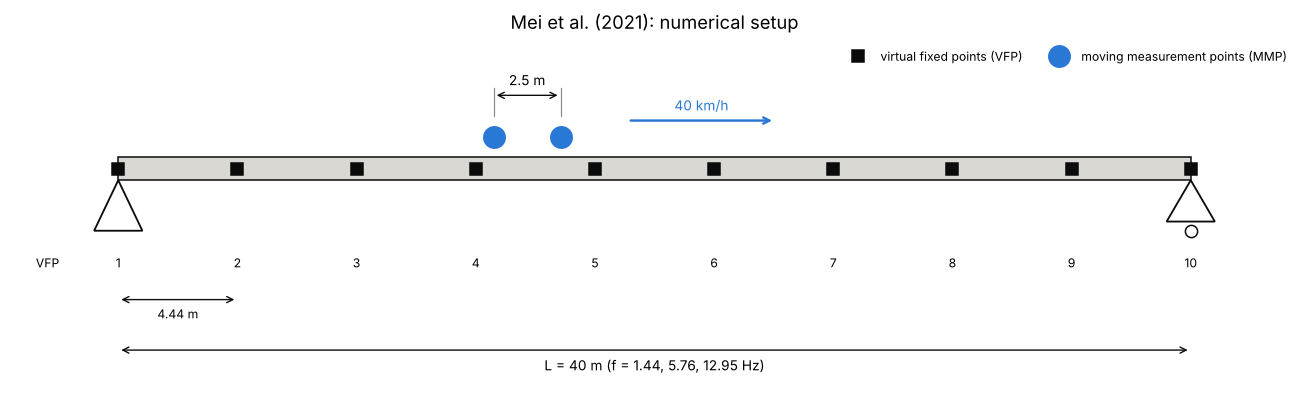

In [6]:
# Figure 2: study setup (40 m beam, 10 VFPs, two moving contact points)
SPAN_MEI = 40.0
vfp_mei = np.linspace(0, SPAN_MEI, 10)
wheel_rear, wheel_front = 14.0, 16.5                    # illustrative instant

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.add_patch(patches.Rectangle((0, -0.5), SPAN_MEI, 0.5, facecolor="#d9d8d3",
                               edgecolor=COLOR_TRUE, lw=1))
ax.add_patch(patches.Polygon([(0, -0.5), (-0.9, -1.6), (0.9, -1.6)], closed=True,
                             facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))   # pin
ax.add_patch(patches.Polygon([(SPAN_MEI, -0.5), (SPAN_MEI - 0.9, -1.4), (SPAN_MEI + 0.9, -1.4)],
                             closed=True, facecolor="white", edgecolor=COLOR_TRUE, lw=1.2))  # roller
ax.plot(SPAN_MEI, -1.6, "o", ms=8, mfc="white", mec=COLOR_TRUE)

# Virtual fixed points
ax.plot(vfp_mei, np.full(10, -0.25), "s", ms=8, color=COLOR_TRUE, label="virtual fixed points (VFP)")
for i, x in enumerate(vfp_mei):
    ax.text(x, -2.3, f"{i + 1}", ha="center", va="center", fontsize=8)
ax.text(-2.2, -2.3, "VFP", ha="right", va="center", fontsize=8)

# Moving contact points (wheels)
ax.plot([wheel_rear, wheel_front], [0.45, 0.45], "o", ms=14, color=COLOR_1,
        label="moving measurement points (MMP)")
ax.annotate("", xy=(wheel_rear, 1.35), xytext=(wheel_front, 1.35),
            arrowprops=dict(arrowstyle="<->", color=COLOR_TRUE, lw=0.9))
ax.text((wheel_rear + wheel_front) / 2, 1.5, "2.5 m", ha="center", va="bottom", fontsize=9)
for x in (wheel_rear, wheel_front):
    ax.plot([x, x], [0.9, 1.5], color=COLOR_SIGNAL, lw=0.8)
ax.annotate("", xy=(24.5, 0.8), xytext=(19.0, 0.8),
            arrowprops=dict(arrowstyle="->", color=COLOR_1, lw=1.6))
ax.text(21.75, 0.95, "40 km/h", ha="center", va="bottom", fontsize=9, color=COLOR_1)

# Dimensions
ax.annotate("", xy=(vfp_mei[0], -3.1), xytext=(vfp_mei[1], -3.1),
            arrowprops=dict(arrowstyle="<->", color=COLOR_TRUE, lw=0.9))
ax.text((vfp_mei[0] + vfp_mei[1]) / 2, -3.25, f"{vfp_mei[1]:.2f} m", ha="center", va="top", fontsize=8)
ax.annotate("", xy=(0, -4.2), xytext=(SPAN_MEI, -4.2),
            arrowprops=dict(arrowstyle="<->", color=COLOR_TRUE, lw=0.9))
ax.text(SPAN_MEI / 2, -4.35, "L = 40 m (f = 1.44, 5.76, 12.95 Hz)", ha="center", va="top", fontsize=9)

ax.set_xlim(-4, 44)
ax.set_ylim(-5.2, 2.6)
ax.axis("off")
ax.legend(loc="upper right", fontsize=8, ncol=2)
ax.set_title("Mei et al. (2021): numerical setup")
fig.tight_layout()
fig.savefig(FIG_DIR / "mei2021_configuracion.png", dpi=150, bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Mei et al. (2021).*

## 6. Suposiciones

**Modelo y vehículo**

- **a.** Los sensores van en los ejes, para evitar el efecto de la suspensión.
- **b.** En la simulación no existe el vehículo: solo hay puntos de contacto, sin suspensión ni llantas. La deformación de las llantas se ignora.
- **c.** La dinámica del vehículo se podría quitar con su función de transferencia empírica, pero no se hizo.
- **d.** La masa del vehículo es despreciable frente a la del puente (sistema lineal e invariante en el tiempo).
- **e.** Todos los vehículos van a la misma velocidad, constante.
- **f.** Cada caso es una sola pasada: primero 1 vehículo (2 MMP), luego 2, 3 y 4 vehículos en convoy (4, 6 y 8 MMP).

**Señal**

- **g.** Señal de referencia limpia: sin rugosidad ni ruido.
- **h.** Integración trapezoidal doble de la aceleración, sin corrección de deriva.
- **i.** No se aplica ningún filtrado ni preprocesado de la señal.

**Procesamiento**

- **j.** Interpolación lineal entre VFP vecinos. Un dato es válido solo si hay al menos dos MMP en la región entre los vecinos del VFP.
- **k.** La matriz es de rango bajo porque pocos modos dominan la respuesta.
- **l.** Las columnas de $U$ de la SVD corresponden a las formas modales por ser ortogonales. Esto se infiere, no se demuestra.
- **m.** $\lambda$ se elige a mano, por el error en los datos conocidos y criterio de ingeniería.

## 7. Métodos y propósito

| Método | Para qué lo usó | Enlace |
|---|---|---|
| Integración trapezoidal doble | Pasar de aceleración a desplazamiento | — |
| Mapeo lineal con pseudoinversa de Moore–Penrose | Llevar los desplazamientos de las ruedas, que se mueven, a puntos fijos del puente | [Mapeo a VFP](../metodos/metodos.ipynb#mapeo-vfp) |
| Soft imputing (Mazumder, Hastie y Tibshirani, 2010) | Completar la matriz con huecos | [Soft imputing](../metodos/metodos.ipynb#soft-imputing) |
| SVD final | Separar la matriz completa en formas modales | [SVD](../metodos/metodos.ipynb#svd-formas-modales) |
| MAC | Medir el parecido con las formas exactas | — |

**Clasificación en la revisión:** Sparse sensing / Matrix completion y Virtual sensors · **Data source:** Single vehicle y Multiple vehicles · **Target:** Mode shapes · **Validation level:** 1 Numerical.

## 8. Validación y resultados

- **Caso ideal, 1 vehículo:** MAC de 1.000, 0.998 y 0.977.
- **2, 3 y 4 vehículos (4, 6 y 8 MMP):** faltantes de 55.40 %, 44.47 % y 33.61 %; MAC de 1.000/0.994/0.947, 1.000/0.986/0.930 y 1.000/0.979/0.956. El error de reconstrucción ronda el 20 % y baja con más MMP, pero el MAC de los modos altos no mejora.
- **Velocidad:** el modo 1 es insensible entre 10 y 80 km/h; los modos 2 y 3 funcionan mejor entre 20 y 60 km/h.
- **Peso:** no influye si el vehículo pesa menos de 1/10 del puente (probado de 500 a 5000 kg).
- **Lagrange de Oshima, en el mismo caso:** el MAC del tercer modo cae a 0.676.
- **$\lambda$:** si es grande, borra los modos altos.
- **Rugosidad alta, sin preprocesado:** MAC de 0.876, 0.750 y 0.492.
- **Ruido del 0 al 5 %** (SNR de 40 a 26 dB): todos los MAC bajan; el modo 1 es el más robusto.

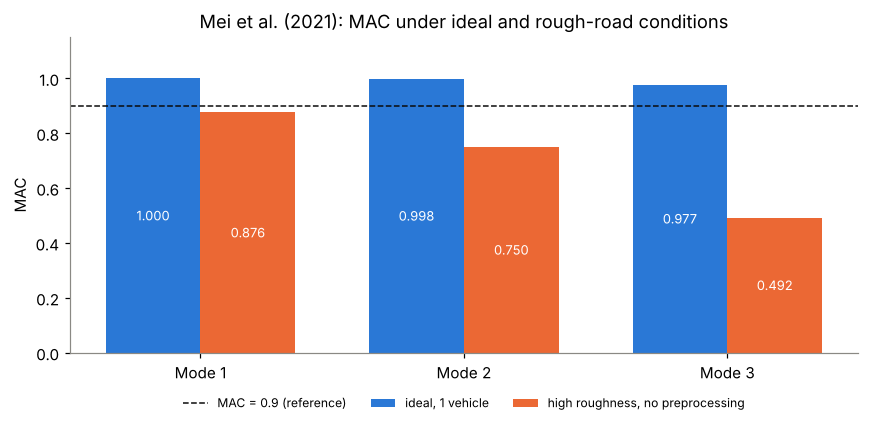

In [7]:
# Figure 3: MAC per mode, ideal (1 vehicle) vs high roughness (no preprocessing)
modes_mei = np.array([1, 2, 3])
mac_ideal = [1.000, 0.998, 0.977]
mac_rough = [0.876, 0.750, 0.492]

fig, ax = plt.subplots(figsize=(8, 4))
bars_ideal = ax.bar(modes_mei - 0.18, mac_ideal, width=0.36, color=COLOR_1, label="ideal, 1 vehicle")
bars_rough = ax.bar(modes_mei + 0.18, mac_rough, width=0.36, color=COLOR_2,
                    label="high roughness, no preprocessing")
for bars in (bars_ideal, bars_rough):
    ax.bar_label(bars, fmt="%.3f", fontsize=8.5, label_type="center", color="white")
ax.axhline(0.9, linestyle="--", color=COLOR_TRUE, lw=1, label="MAC = 0.9 (reference)")
ax.set_xticks(modes_mei)
ax.set_xticklabels([f"Mode {k}" for k in modes_mei])
ax.set_ylim(0, 1.15)
ax.set_ylabel("MAC")
ax.set_title("Mei et al. (2021): MAC under ideal and rough-road conditions")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "mei2021_mac_condiciones.png", dpi=150, bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Mei et al. (2021).*

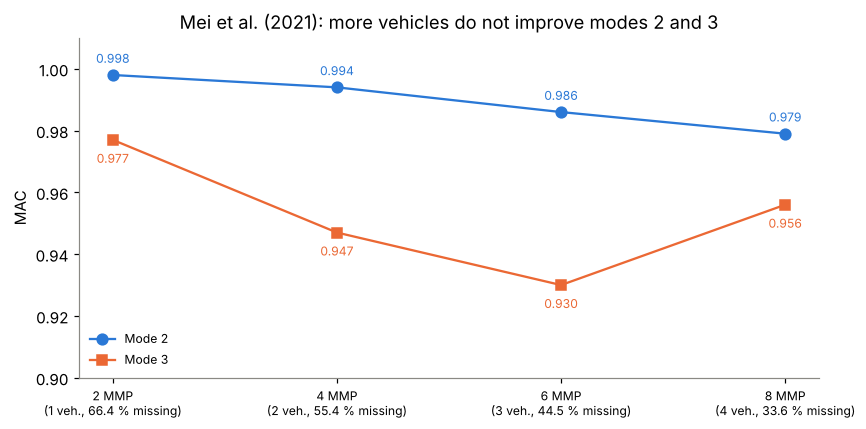

In [8]:
# Figure 4: MAC of modes 2 and 3 vs number of moving measurement points
n_mmp = np.array([2, 4, 6, 8])
missing_pct = [66.41, 55.40, 44.47, 33.61]
mac_mode_2 = [0.998, 0.994, 0.986, 0.979]
mac_mode_3 = [0.977, 0.947, 0.930, 0.956]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(n_mmp, mac_mode_2, "o-", ms=7, color=COLOR_1, label="Mode 2")
ax.plot(n_mmp, mac_mode_3, "s-", ms=7, color=COLOR_2, label="Mode 3")
for x, y2, y3 in zip(n_mmp, mac_mode_2, mac_mode_3):
    ax.annotate(f"{y2:.3f}", (x, y2), textcoords="offset points", xytext=(0, 8), ha="center",
                fontsize=8, color=COLOR_1)
    ax.annotate(f"{y3:.3f}", (x, y3), textcoords="offset points", xytext=(0, -15), ha="center",
                fontsize=8, color=COLOR_2)
ax.set_xticks(n_mmp)
ax.set_xticklabels([f"{n} MMP\n({n // 2} veh., {m:.1f} % missing)" for n, m in zip(n_mmp, missing_pct)],
                   fontsize=8)
ax.set_ylim(0.90, 1.01)
ax.set_ylabel("MAC")
ax.set_title("Mei et al. (2021): more vehicles do not improve modes 2 and 3")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "mei2021_mac_vehiculos.png", dpi=150, bbox_inches="tight")
plt.show()

*Esquema propio basado en la descripción de Mei et al. (2021).*

## 9. Limitaciones

- Solo validación numérica, sin laboratorio ni campo.
- La señal ideal no incluye dinámica del vehículo, rugosidad ni ruido.
- Al agregar rugosidad y ruido, la señal entró cruda, sin restar entre ruedas ni separar fuentes, y el MAC del tercer modo cayó de 0.977 a 0.49.
- Al aumentar el número de vehículos, el MAC de los modos 2 y 3 no mejora; incluso baja (modo 2: 0.998 → 0.994 → 0.986 → 0.979), aunque el error de reconstrucción de la matriz sí disminuye. La caída no es uniforme: el modo 3 baja con 4 y 6 MMP y sube con 8. Los autores lo atribuyen a que la matriz de mapeo con 2 MMP es de menor dimensión y más estable ante la pseudoinversa, pero no lo demuestran y reconocen que hace falta investigarlo.
- Deriva de integración no tratada; velocidad constante e igual en todos los vehículos; viga simple y uniforme.
- $\lambda$ manual.
- Datos disponibles solo a petición.

## 10. Conclusiones

- Con señal limpia, el método es muy preciso: identifica tres modos con un solo vehículo, a velocidad de tráfico, sin dominio de la frecuencia y con signo correcto.
- Su desempeño depende mucho de la calidad de la señal: con rugosidad alta se degrada fuertemente, sobre todo en los modos altos.
- Falta validarlo en un caso más realista, de una de dos formas: (1) una validación numérica que incluya vehículo con suspensión, rugosidad, ruido y el procesamiento de señal correspondiente; o (2) directamente en campo.
- Los propios autores anuncian estudios experimentales y la selección automática de $\lambda$ como trabajo futuro.

### Posibles líneas de investigación

- **Validación realista:** simulación con vehículo completo (suspensión y llantas), rugosidad y ruido, aplicando preprocesado (resta entre ruedas, separación de fuentes) antes del método; o prueba de campo.
- **Explicar por qué más vehículos no mejoran la identificación de los modos altos.** Hipótesis a comprobar:
  1. Inestabilidad de la pseudoinversa en el mapeo con más MMP (explicación de los autores).
  2. Registro más corto: la simulación termina cuando el primer eje llega al final, así que un convoy más largo da menos instantes (677 con 1 vehículo frente a 407 con 4) y menos ciclos de los modos altos.
  3. Mayor carga sobre el puente: la deflexión cuasiestática, parecida al modo 1, domina más la señal y los modos 2 y 3 quedan relativamente más débiles.

  > 📝 Las hipótesis 2 y 3 son **propias de esta revisión**, no de los autores.
- **Selección automática de $\lambda$.**

[↑ Volver al índice](#indice)